<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/01_Data_Cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Direct link to the raw data in your GitHub repository
raw_data_url = 'https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/refs/heads/main/data/CPM24.20261012T141046.csv'

# Load the raw dataset automatically
df = pd.read_csv(raw_data_url)

print("Successfully loaded raw dataset directly from GitHub!")
df.head()

Successfully loaded raw dataset directly from GitHub!


,Statistic Label,Month,Detailed Sub Indices,UNIT,VALUE
0,Consumer Price Index,2016 January,Food and non-alcoholic beverages,Base Month December 2023=100,90.7
1,Consumer Price Index,2016 January,Diesel,Base Month December 2023=100,65.0
2,Consumer Price Index,2016 January,Petrol,Base Month December 2023=100,72.8
3,Consumer Price Index,2016 February,Food and non-alcoholic beverages,Base Month December 2023=100,90.0
4,Consumer Price Index,2016 February,Diesel,Base Month December 2023=100,61.1


In [23]:
# 1. Pivot the data: turn categories into separate columns indexed by Month
df_pivot = df.pivot(
    index="Month", columns="Detailed Sub Indices", values="VALUE"
).reset_index()

# 2. Convert the 'Month' text string (e.g., '2016 January') into a true datetime object
# This ensures Python knows the exact chronological order of the dates
df_pivot["Month_DT"] = pd.to_datetime(df_pivot["Month"], format="%Y %B")

# 3. Sort chronologically from oldest to newest
df_pivot = df_pivot.sort_values("Month_DT").reset_index(drop=True)

# 4. Check the cleaned and reshaped data preview
print("Cleaned Data Preview:")
print(df_pivot.head())

Cleaned Data Preview:
Detailed Sub Indices          Month  Diesel  Food and non-alcoholic beverages  \
0                      2016 January    65.0                              90.7   
1                     2016 February    61.1                              90.0   
2                        2016 March    61.9                              90.3   
3                        2016 April    64.2                              90.0   
4                          2016 May    65.3                              90.0   

Detailed Sub Indices  Petrol   Month_DT  
0                       72.8 2016-01-01  
1                       70.5 2016-02-01  
2                       70.0 2016-03-01  
3                       73.1 2016-04-01  
4                       74.7 2016-05-01  


In [24]:
# View the last 5 rows to see your 2026 data
print(df_pivot.tail())

Detailed Sub Indices           Month  Diesel  \
124                         2026 May   116.0   
125                        2026 June   109.6   
126                        2026 July   102.6   
127                      2026 August   113.9   
128                   2026 September   120.0   

Detailed Sub Indices  Food and non-alcoholic beverages  Petrol   Month_DT  
124                                              106.6   109.3 2026-05-01  
125                                              106.2   108.1 2026-06-01  
126                                              106.4   103.7 2026-07-01  
127                                              106.3   109.3 2026-08-01  
128                                              106.4   114.5 2026-09-01  


In [25]:
# Check the very beginning of the dataset
print("--- START OF DATA ---")
print(df_pivot.head(3))

# Check the very end of the dataset
print("\n--- END OF DATA ---")
print(df_pivot.tail(3))

--- START OF DATA ---
Detailed Sub Indices          Month  Diesel  Food and non-alcoholic beverages  \
0                      2016 January    65.0                              90.7   
1                     2016 February    61.1                              90.0   
2                        2016 March    61.9                              90.3   

Detailed Sub Indices  Petrol   Month_DT  
0                       72.8 2016-01-01  
1                       70.5 2016-02-01  
2                       70.0 2016-03-01  

--- END OF DATA ---
Detailed Sub Indices           Month  Diesel  \
126                        2026 July   102.6   
127                      2026 August   113.9   
128                   2026 September   120.0   

Detailed Sub Indices  Food and non-alcoholic beverages  Petrol   Month_DT  
126                                              106.4   103.7 2026-07-01  
127                                              106.3   109.3 2026-08-01  
128                                        

In [26]:
import pandas as pd

print("=== 1. DATASET SHAPE & STRUCTURE ===")
print(f"Total rows: {len(df_pivot)}")
print(f"Date range: {df_pivot['Month'].iloc[0]} to {df_pivot['Month'].iloc[-1]}")

print("\n=== 2. MISSING VALUE AUDIT ===")
missing_counts = df_pivot.isnull().sum()
print(missing_counts)
if missing_counts.sum() == 0:
    print(
        "✅ SUCCESS: Zero missing values found across all categories and months!"
    )
else:
    print("⚠️ WARNING: Missing values detected.")

print("\n=== 3. STATISTICAL HEALTH SUMMARY ===")
# Display statistical breakdown (mean, min, max, std) for each category
stats = df_pivot[["Diesel", "Petrol", "Food and non-alcoholic beverages"]].describe()
print(stats)

print("\n=== 4. CHRONOLOGICAL CONTINUITY CHECK ===")
# Verify that months are properly spaced without any unexpected gaps
df_pivot["Month_Diff"] = df_pivot["Month_DT"].diff()
gaps = df_pivot[df_pivot["Month_Diff"] > pd.Timedelta(days=31)]
if len(gaps) == 0:
    print(
        "✅ SUCCESS: Timeline is fully continuous with monthly step-intervals!"
    )
else:
    print("⚠️ WARNING: Gaps found in the timeline:", gaps)

=== 1. DATASET SHAPE & STRUCTURE ===
Total rows: 129
Date range: 2016 January to 2026 September

=== 2. MISSING VALUE AUDIT ===
Detailed Sub Indices
Month                               0
Diesel                              0
Food and non-alcoholic beverages    0
Petrol                              0
Month_DT                            0
dtype: int64
✅ SUCCESS: Zero missing values found across all categories and months!

=== 3. STATISTICAL HEALTH SUMMARY ===
Detailed Sub Indices      Diesel      Petrol  Food and non-alcoholic beverages
count                 129.000000  129.000000                        129.000000
mean                   87.556589   91.182946                         92.140310
std                    16.032807   12.577088                          8.138302
min                    61.100000   70.000000                         82.800000
25%                    73.500000   79.800000                         85.500000
50%                    81.600000   87.000000                    

In [27]:
# Calculate correlation coefficients between fuel and food
correlation_matrix = df_pivot[
    ["Diesel", "Petrol", "Food and non-alcoholic beverages"]
].corr()
print("--- PRICE CORRELATION MATRIX ---")
print(correlation_matrix)

--- PRICE CORRELATION MATRIX ---
Detailed Sub Indices                Diesel    Petrol  \
Detailed Sub Indices                                   
Diesel                            1.000000  0.979720   
Petrol                            0.979720  1.000000   
Food and non-alcoholic beverages  0.687407  0.675527   

Detailed Sub Indices              Food and non-alcoholic beverages  
Detailed Sub Indices                                                
Diesel                                                    0.687407  
Petrol                                                    0.675527  
Food and non-alcoholic beverages                          1.000000  


In [28]:
# Test the correlation between Diesel and Food prices across different time delays (lags)
lag_results = {}
for lag in range(7):
    # Shift diesel prices forward by 'lag' months to see if food prices follow later
    corr = (
        df_pivot["Diesel"]
        .shift(lag)
        .corr(df_pivot["Food and non-alcoholic beverages"])
    )
    lag_results[f"{lag} Month(s) Lag"] = corr

# Display the results
for lag_name, correlation in lag_results.items():
    print(f"{lag_name}: Correlation = {correlation:.4f}")

0 Month(s) Lag: Correlation = 0.6874
1 Month(s) Lag: Correlation = 0.7011
2 Month(s) Lag: Correlation = 0.7142
3 Month(s) Lag: Correlation = 0.7329
4 Month(s) Lag: Correlation = 0.7478
5 Month(s) Lag: Correlation = 0.7601
6 Month(s) Lag: Correlation = 0.7722


In [29]:
df_pivot.to_csv("cleaned_fuel_grocery_data.csv", index=False)

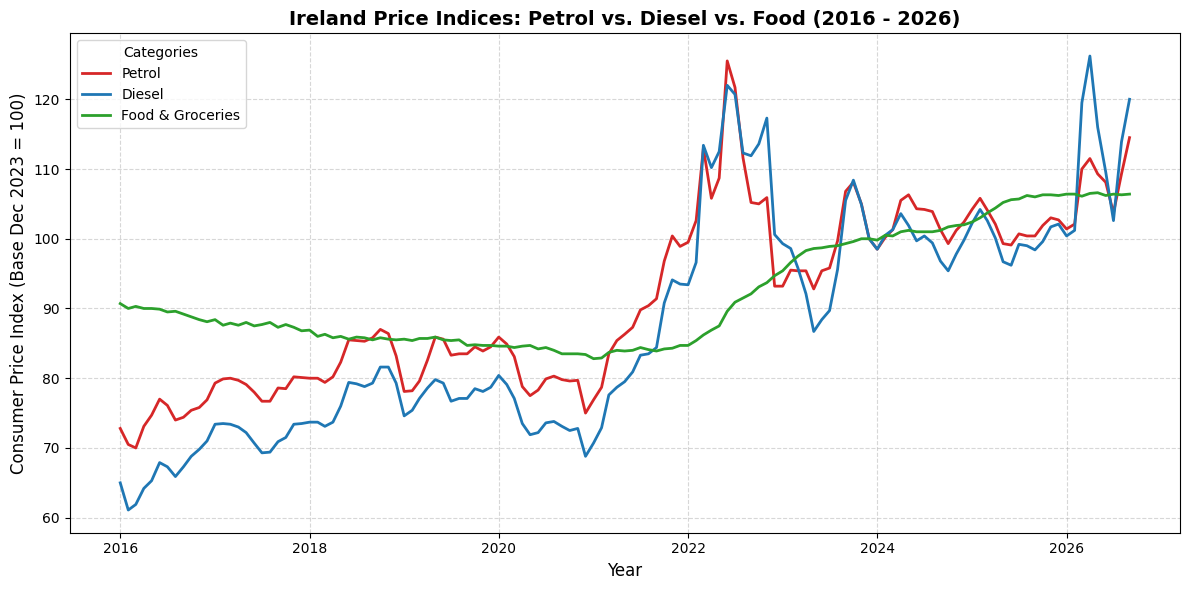

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure size
plt.figure(figsize=(12, 6))

# Plot Petrol, Diesel, and Food index trends over time
sns.lineplot(
    data=df_pivot,
    x="Month_DT",
    y="Petrol",
    label="Petrol",
    linewidth=2,
    color="tab:red",
)
sns.lineplot(
    data=df_pivot,
    x="Month_DT",
    y="Diesel",
    label="Diesel",
    linewidth=2,
    color="tab:blue",
)
sns.lineplot(
    data=df_pivot,
    x="Month_DT",
    y="Food and non-alcoholic beverages",
    label="Food & Groceries",
    linewidth=2,
    color="tab:green",
)

# Add titles, labels, and formatting
plt.title(
    "Ireland Price Indices: Petrol vs. Diesel vs. Food (2016 - 2026)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Consumer Price Index (Base Dec 2023 = 100)", fontsize=12)
plt.legend(title="Categories")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Save the chart image locally in Colab so you can download it
plt.savefig("fuel_vs_grocery_trend.png", dpi=300)

# Display the chart right here in the notebook
plt.show()